In [13]:
# For extreme DDA prices.

import polars as pl
fcs= pl.read_parquet("forecast_result.parquet")
daa = pl.read_parquet("daa_price.parquet")
daa = daa.select(pl.col("delivery_start").dt.convert_time_zone("UTC"),pl.col("daa_price"))

result =(
    daa
    .join(fcs, on="delivery_start", how="full",coalesce=True)

) 
print("DAA Prices and Residual Load Forecast")
display(result)

DAA Prices and Residual Load Forecast


delivery_start,daa_price,entsoe,enappsys,energy_weather,GFS_ENS,EC_OP,EC_46,GFS_OP,EC_AIFS,EC_ENS,EC_AIFS_ENS,tech_avail
"datetime[μs, UTC]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2026-01-01 00:00:00 UTC,60.01,8469.0,10310.0,null,6870.44,6489.05,10183.42,3739.45,8379.26,7036.98,null,-2660.471509
2026-01-01 00:15:00 UTC,48.9,7208.0,9457.0,null,6180.66,6216.17,10183.42,3088.67,7693.09,6318.96,null,-3729.071544
2026-01-01 00:30:00 UTC,36.74,6298.0,9083.0,null,5369.82,6189.5,10183.42,2499.47,6412.5,5401.69,null,-4641.857449
2026-01-01 00:45:00 UTC,23.93,5804.0,8311.0,null,4377.39,5455.32,10183.42,2295.28,6513.04,4935.19,null,-5460.320099
2026-01-01 01:00:00 UTC,36.01,4976.0,8055.0,null,3175.97,5328.14,7598.38,2008.71,5514.48,4834.84,null,-6194.019856
…,…,…,…,…,…,…,…,…,…,…,…,…
2026-08-31 23:15:00 UTC,146.05,null,null,null,null,null,null,null,null,null,null,17403.638161
2026-08-31 23:30:00 UTC,146.19,null,null,null,5529.26,11703.08,10376.89,5542.55,14044.53,8583.28,11692.38,null
2026-08-31 23:30:00 UTC,146.19,null,null,null,null,null,null,null,null,null,null,17548.877713


In [14]:
# extreme high, low daa prices Jan- Aug

import polars as pl

providers = [
    "entsoe",
    "enappsys",
    "energy_weather",
    "EC_ENS"
]

# January-August data
df_jan_aug = (
    result
    .with_columns(
        pl.col("delivery_start").dt.month().alias("month")
    )
    .filter(
        pl.col("month").is_between(1, 8)
    )
)

# Global DAA price thresholds
low_threshold = df_jan_aug["daa_price"].quantile(0.05)
high_threshold = df_jan_aug["daa_price"].quantile(0.95)

print(f"Extreme Low threshold:  {low_threshold:.2f} €/MWh")
print(f"Extreme High threshold: {high_threshold:.2f} €/MWh")


# Keep only extreme observations + 4 forecasts
extreme_result = (
    df_jan_aug
    .filter(
        (pl.col("daa_price") <= low_threshold) |
        (pl.col("daa_price") >= high_threshold)
    )
    .with_columns(
        pl.when(pl.col("daa_price") >= high_threshold)
        .then(pl.lit("Extreme High"))
        .otherwise(pl.lit("Extreme Low"))
        .alias("extreme_type")
    )
    .select([
        "delivery_start",
        "month",
        "daa_price",
        "extreme_type",
        "entsoe",
        "enappsys",
        "energy_weather",
        "EC_ENS"
    ])
    .sort("delivery_start")
)

display(extreme_result)

Extreme Low threshold:  -0.10 €/MWh
Extreme High threshold: 182.64 €/MWh


delivery_start,month,daa_price,extreme_type,entsoe,enappsys,energy_weather,EC_ENS
"datetime[μs, UTC]",i8,f64,str,f64,f64,f64,f64
2026-01-05 15:30:00 UTC,1,193.19,"""Extreme High""",56044.0,59656.0,null,52283.73
2026-01-05 15:45:00 UTC,1,198.71,"""Extreme High""",56433.0,60299.0,null,52406.18
2026-01-05 16:00:00 UTC,1,198.13,"""Extreme High""",56800.0,60619.0,null,52182.66
2026-01-05 16:15:00 UTC,1,208.0,"""Extreme High""",57612.0,61313.0,null,52551.13
2026-01-05 16:30:00 UTC,1,244.39,"""Extreme High""",57878.0,61884.0,null,52428.89
…,…,…,…,…,…,…,…
2026-08-31 17:45:00 UTC,8,207.51,"""Extreme High""",null,25629.0,null,23922.59
2026-08-31 18:15:00 UTC,8,190.95,"""Extreme High""",null,25529.0,null,22168.33
2026-08-31 18:30:00 UTC,8,197.6,"""Extreme High""",null,25521.0,null,21845.35


In [15]:
df_logit = (
    df_jan_aug
    .with_columns(
        (pl.col("daa_price") >= high_threshold)
        .cast(pl.Int8)
        .alias("extreme_high")
    )
    .with_columns(
        pl.col("delivery_start").dt.hour().alias("hour"),
        (pl.col("delivery_start").dt.weekday() >= 6)
        .cast(pl.Int8)
        .alias("weekend")
    )
)
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

providers = [
    "entsoe",
    "enappsys",
    "energy_weather",
    "EC_ENS"
]

logit_models_high = {}
results_high = []

for provider in providers:

    # Remove nulls only for this specific provider
    clean = (
        df_logit
        .select([
            "extreme_high",
            provider,
            "weekend",
            "hour",
            "month"
        ])
        .drop_nulls()
        .to_pandas()
    )

    # Convert MW → GW
    clean[f"{provider}_GW"] = clean[provider] / 1000

    # Logistic regression
    formula = (
        f"extreme_high ~ {provider}_GW "
        "+ weekend + C(hour) + C(month)"
    )

    model = smf.logit(
        formula,
        data=clean
    ).fit(disp=False)

    logit_models_high[provider] = model

    variable = f"{provider}_GW"

    # Odds ratio
    odds_ratio = np.exp(model.params[variable])

    # 95% confidence interval for odds ratio
    ci = np.exp(model.conf_int().loc[variable])

    results_high.append({
        "provider": provider,
        "N": len(clean),
        "coefficient": model.params[variable],
        "odds_ratio": odds_ratio,
        "CI_lower": ci.iloc[0],
        "CI_upper": ci.iloc[1],
        "p_value": model.pvalues[variable],
        "pseudo_R2": model.prsquared
    })

extreme_high_logit_results = pd.DataFrame(results_high)

display(extreme_high_logit_results)

c:\Users\HanhTa\project\jerry\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\HanhTa\project\jerry\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\HanhTa\project\jerry\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\HanhTa\project\jerry\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,provider,N,coefficient,odds_ratio,CI_lower,CI_upper,p_value,pseudo_R2
0,entsoe,17264,0.371858,1.450426,1.413156,1.488679,1.743149e-172,0.653259
1,enappsys,24625,0.236572,1.266898,1.248205,1.285871,1.374051e-213,0.556510
2,energy_weather,19304,0.266133,1.304908,1.280070,1.330228,3.107078e-162,0.607490
3,EC_ENS,25444,0.306739,1.358986,1.334302,1.384127,6.464792e-236,0.620786


In [16]:
# Precision- Recall Curve : estimate optimal probability threshold. 


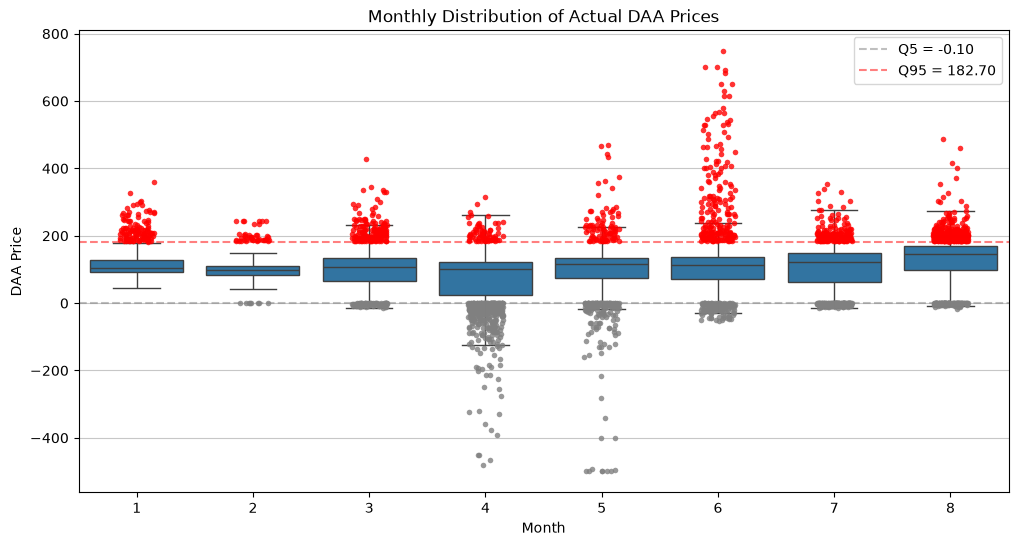

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plot_df = (
    result
    .select(["delivery_start", "daa_price"])
    .to_pandas()
)

plot_df["delivery_start"] = pd.to_datetime(plot_df["delivery_start"])
plot_df["month"] = plot_df["delivery_start"].dt.month

# Global thresholds (entire Jan-Aug period)
q05 = plot_df["daa_price"].quantile(0.05)
q95 = plot_df["daa_price"].quantile(0.95)

low_extreme = plot_df[plot_df["daa_price"] <= q05]
high_extreme = plot_df[plot_df["daa_price"] >= q95]

plt.figure(figsize=(12, 6))

# Hide default outliers
sns.boxplot(
    data=plot_df,
    x="month",
    y="daa_price",
    showfliers=False
)

# Bottom 5%
sns.stripplot(
    data=low_extreme,
    x="month",
    y="daa_price",
    color="grey",
    size=4,
    jitter=0.15,
    alpha=0.8
)

# Top 5%
sns.stripplot(
    data=high_extreme,
    x="month",
    y="daa_price",
    color="red",
    size=4,
    jitter=0.15,
    alpha=0.8
)

plt.axhline(q05, color="grey", linestyle="--", alpha=0.5, label=f"Q5 = {q05:.2f}")
plt.axhline(q95, color="red", linestyle="--", alpha=0.5, label=f"Q95 = {q95:.2f}")

plt.title("Monthly Distribution of Actual DAA Prices")
plt.xlabel("Month")
plt.ylabel("DAA Price")
plt.grid(axis="y", alpha=0.7)

plt.legend()
plt.show()

,High (>=Q95),Low (<=Q5)
hour,,
0,0.0,3.0
1,0.0,4.0
2,0.0,4.0
3,3.0,4.0
4,33.0,4.0
5,58.0,4.0
6,61.0,10.0
7,40.0,28.0
8,14.0,65.0


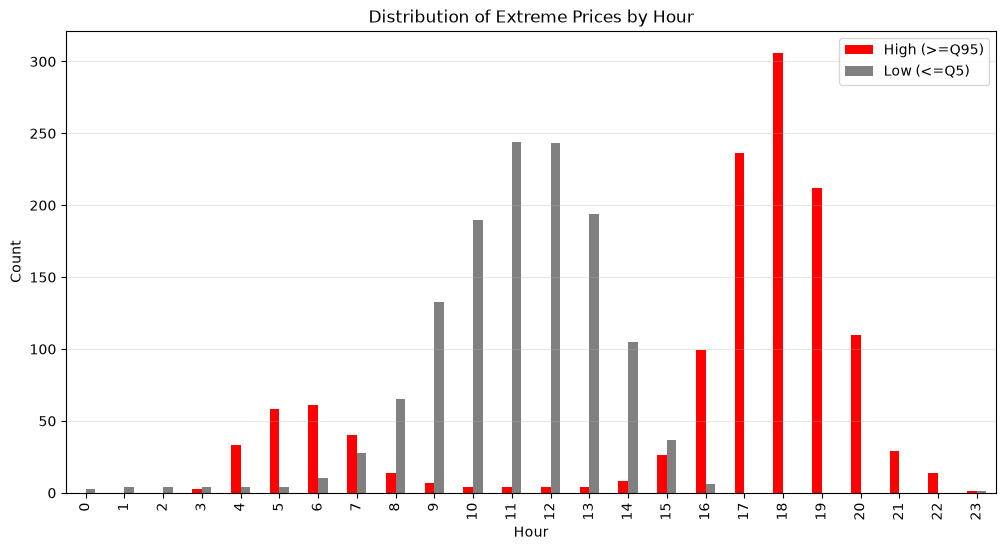

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plot_df = (
    result
    .select(["delivery_start", "daa_price"])
    .to_pandas()
)

plot_df["delivery_start"] = pd.to_datetime(plot_df["delivery_start"])

# Global thresholds
q05 = plot_df["daa_price"].quantile(0.05)
q95 = plot_df["daa_price"].quantile(0.95)

# Extreme prices
high = plot_df[plot_df["daa_price"] >= q95].copy()
low = plot_df[plot_df["daa_price"] <= q05].copy()

high["hour"] = high["delivery_start"].dt.hour
low["hour"] = low["delivery_start"].dt.hour

high_count = high.groupby("hour").size()
low_count = low.groupby("hour").size()

hour_dist = pd.DataFrame({
    "High (>=Q95)": high_count,
    "Low (<=Q5)": low_count
}).fillna(0)

display(hour_dist)

hour_dist.plot(
    kind="bar",
    figsize=(12,6),
    color=["red", "grey"]
)

plt.title("Distribution of Extreme Prices by Hour")
plt.xlabel("Hour")
plt.ylabel("Count")
plt.grid(axis="y", alpha=0.3)
plt.show()

,High (>=Q95),Low (<=Q5)
quarter_hour,,
00:15,0.0,1.0
00:30,0.0,1.0
00:45,0.0,1.0
01:00,0.0,1.0
01:15,0.0,1.0
...,...,...
22:00,12.0,0.0
22:15,1.0,0.0
22:30,1.0,0.0


<Figure size 1800x600 with 0 Axes>

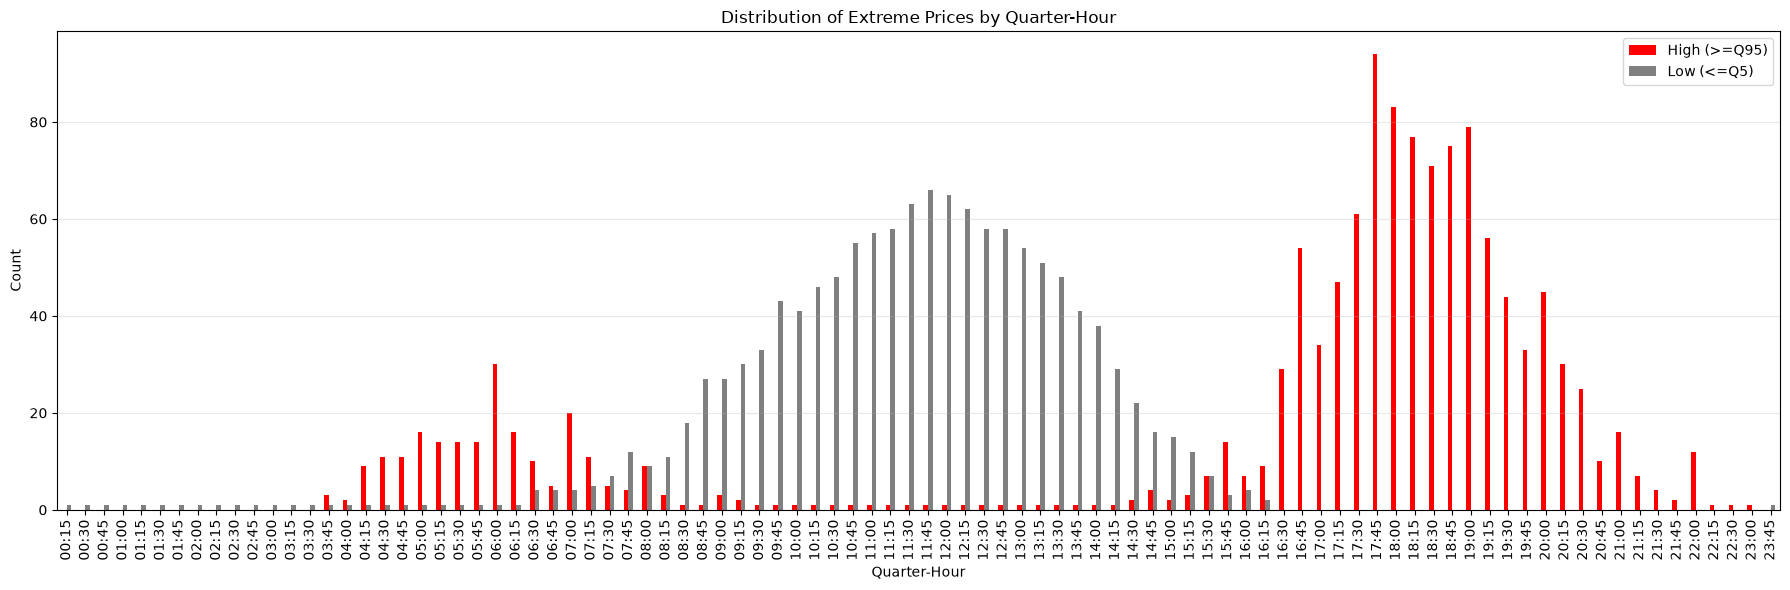

In [26]:
high["quarter_hour"] = (
    high["delivery_start"].dt.strftime("%H:%M")
)

low["quarter_hour"] = (
    low["delivery_start"].dt.strftime("%H:%M")
)

qh_dist = pd.DataFrame({
    "High (>=Q95)": high.groupby("quarter_hour").size(),
    "Low (<=Q5)": low.groupby("quarter_hour").size(),
}).fillna(0)

qh_dist = qh_dist.sort_index()

display(qh_dist)

plt.figure(figsize=(18,6))

qh_dist.plot(
    kind="bar",
    figsize=(18,6),
    color=["red", "grey"]
)

plt.title("Distribution of Extreme Prices by Quarter-Hour")
plt.xlabel("Quarter-Hour")
plt.ylabel("Count")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [21]:
# AP (average precision), PR-AUC
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    auc
)
import pandas as pd

providers = [
    "entsoe",
    "enappsys",
    "energy_weather",
    "EC_ENS"
]

pr_results = []

for provider in providers:

    clean = (
        df_logit
        .select([
            "extreme_high",
            provider,
            "weekend",
            "hour",
            "month"
        ])
        .drop_nulls()
        .to_pandas()
    )

    # Convert MW to GW
    clean[f"{provider}_GW"] = clean[provider] / 1000

    model = logit_models_high[provider]

    # Predicted probabilities
    pred_prob = model.predict(clean)

    # Average Precision (AP)
    average_precision = average_precision_score(
        clean["extreme_high"],
        pred_prob
    )

    # Precision-Recall curve
    precision, recall, _ = precision_recall_curve(
        clean["extreme_high"],
        pred_prob
    )

    # PR-AUC using trapezoidal integration
    pr_auc = auc(recall, precision)

    # Baseline = proportion of Extreme High observations
    baseline = clean["extreme_high"].mean()

    pr_results.append({
        "Provider": provider.upper(),
        "Average Precision": average_precision,
        "PR-AUC": pr_auc,
        "Baseline": baseline
    })


# Results table
pr_auc_table = pd.DataFrame(pr_results)

print(
    pr_auc_table.round(3).to_string(index=False)
)


      Provider  Average Precision  PR-AUC  Baseline
        ENTSOE              0.782   0.782     0.058
      ENAPPSYS              0.646   0.645     0.052
ENERGY_WEATHER              0.721   0.721     0.054
        EC_ENS              0.734   0.734     0.050



Precision-Recall Performance
      Provider  Average Precision  PR-AUC  Baseline     N
        ENTSOE              0.782   0.782     0.058 17264
      ENAPPSYS              0.646   0.645     0.052 24625
ENERGY_WEATHER              0.721   0.721     0.054 19304
        EC_ENS              0.734   0.734     0.050 25444


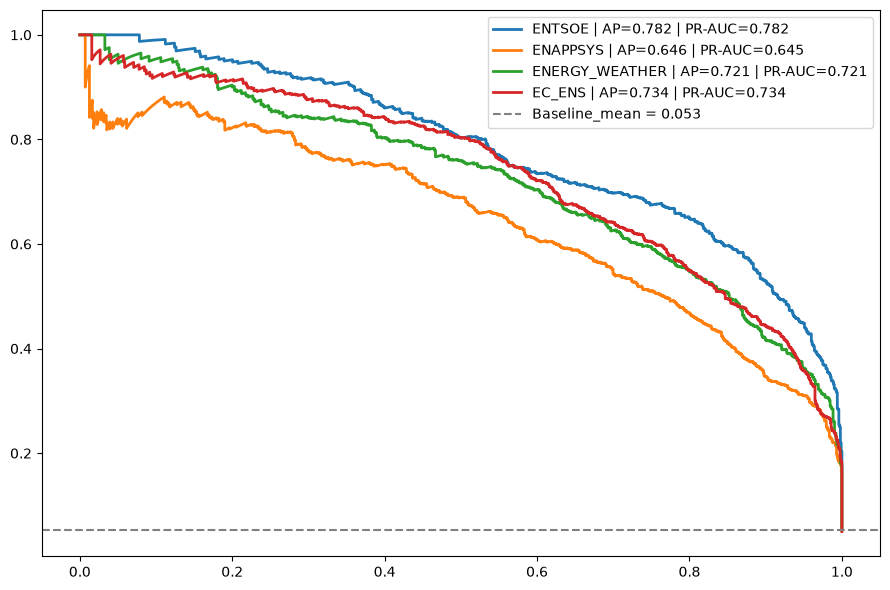

In [22]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    auc
)
import matplotlib.pyplot as plt
import pandas as pd

providers = [
    "entsoe",
    "enappsys",
    "energy_weather",
    "EC_ENS"
]

pr_results = []

plt.figure(figsize=(9, 6))

for provider in providers:

    clean = (
        df_logit
        .select([
            "extreme_high",
            provider,
            "weekend",
            "hour",
            "month"
        ])
        .drop_nulls()
        .to_pandas()
    )

    # Convert MW to GW
    clean[f"{provider}_GW"] = clean[provider] / 1000

    # Logistic regression model
    model = logit_models_high[provider]

    # Predicted probabilities
    pred_prob = model.predict(clean)

    # Actual labels
    y_true = clean["extreme_high"]

    # ---------------------------------------
    # Precision-Recall Curve
    # ---------------------------------------
    precision, recall, thresholds = precision_recall_curve(
        y_true,
        pred_prob
    )

    # Average Precision
    ap = average_precision_score(
        y_true,
        pred_prob
    )

    # PR-AUC
    pr_auc = auc(
        recall,
        precision
    )

    # Baseline
    baseline = y_true.mean()

    # Save results for table
    pr_results.append({
        "Provider": provider.upper(),
        "Average Precision": ap,
        "PR-AUC": pr_auc,
        "Baseline": baseline,
        "N": len(clean)
    })

    # Plot PR curve
    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=(
            f"{provider.upper()} | "
            f"AP={ap:.3f} | "
            f"PR-AUC={pr_auc:.3f}"
        )
    )


# ---------------------------------------
# Results Table
# ---------------------------------------

pr_table = pd.DataFrame(pr_results)

print("\nPrecision-Recall Performance")
print("=" * 70)

print(
    pr_table.round(3).to_string(index=False)
)


# ---------------------------------------
# Baseline
# ---------------------------------------

# Mean baseline across providers
baseline_mean = pr_table["Baseline"].mean().round(3)

plt.axhline(
    y=baseline_mean,
    linestyle="--",
    color="grey",
    label=f"Baseline_mean = {baseline_mean:.3f}"
)
plt.legend()


plt.tight_layout()

plt.show()


# --------------------------------

ENTSOE | Recall = 0.782 | Precision = 0.659 | F1 = 0.715


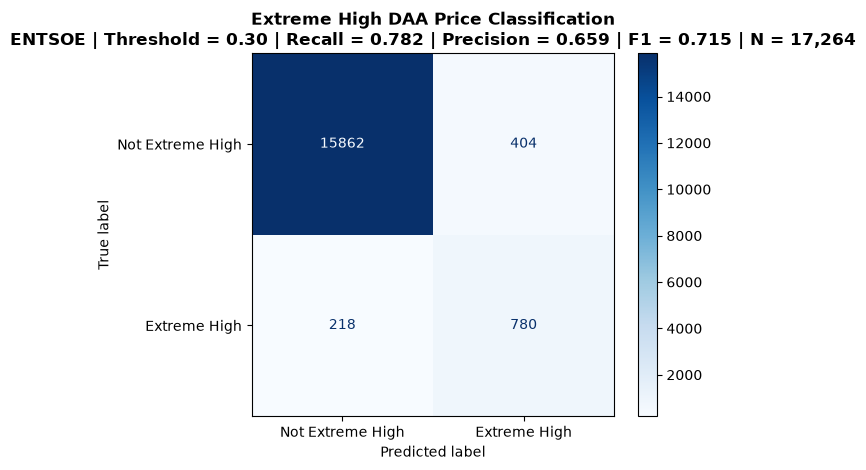

ENAPPSYS | Recall = 0.667 | Precision = 0.578 | F1 = 0.619


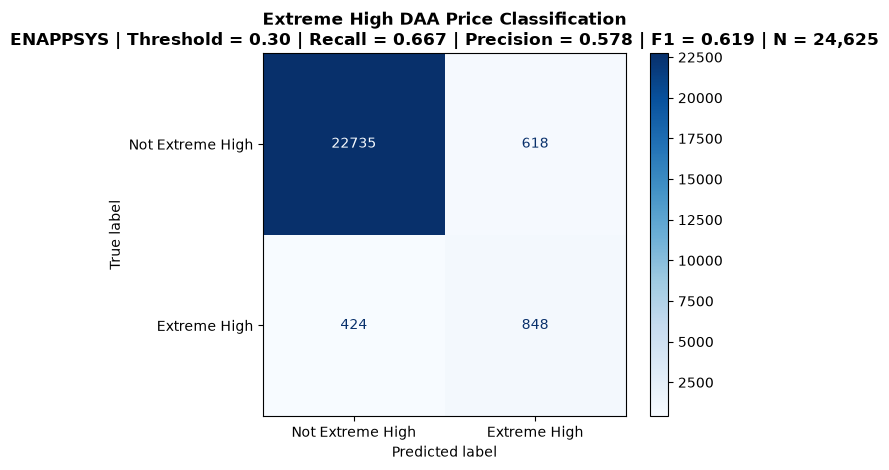

ENERGY_WEATHER | Recall = 0.714 | Precision = 0.610 | F1 = 0.658


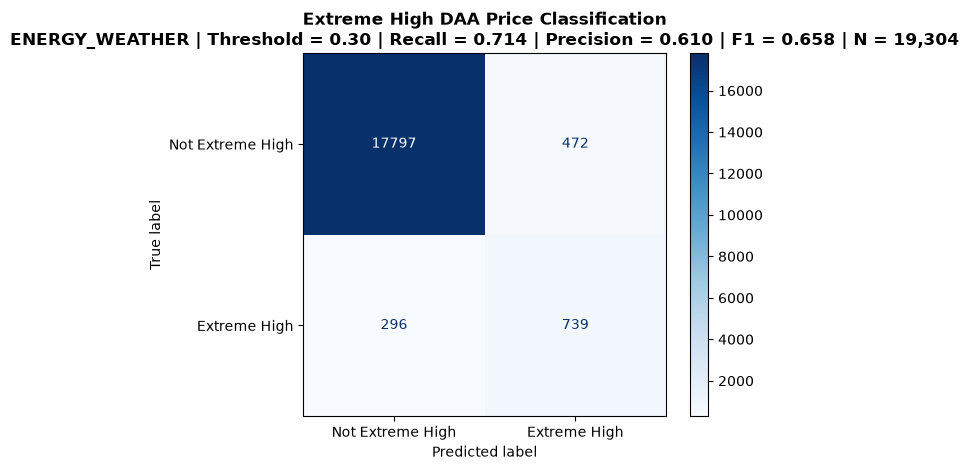

EC_ENS | Recall = 0.734 | Precision = 0.619 | F1 = 0.671


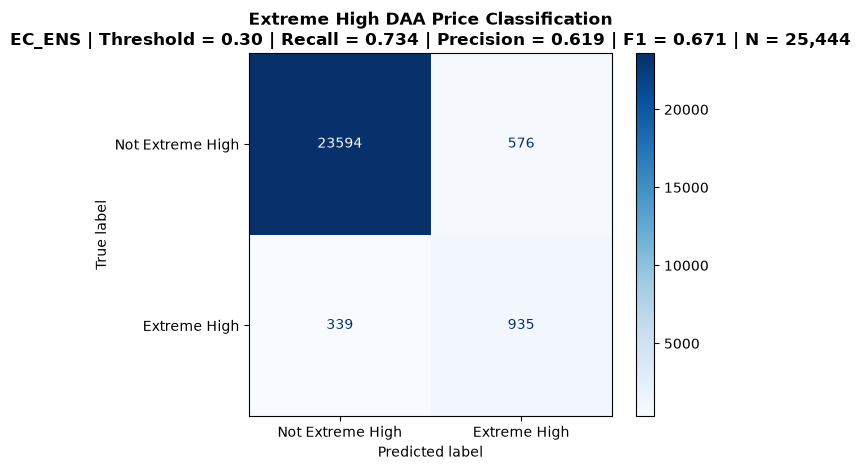

In [23]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    recall_score,
    precision_score,
    f1_score
)
import matplotlib.pyplot as plt

providers = [
    "entsoe",
    "enappsys",
    "energy_weather",
    "EC_ENS"
]

for provider in providers:

    clean = (
        df_logit
        .select([
            "extreme_high",
            provider,
            "weekend",
            "hour",
            "month"
        ])
        .drop_nulls()
        .to_pandas()
    )

    # Convert MW to GW
    clean[f"{provider}_GW"] = clean[provider] / 1000

    model = logit_models_high[provider]

    # Predicted probabilities
    pred_prob = model.predict(clean)

    # Classification
    threshold = 0.3
    pred_class = (pred_prob >= threshold).astype(int)

    # Confusion matrix
    cm = confusion_matrix(
        clean["extreme_high"],
        pred_class
    )

    # Performance metrics
    recall = recall_score(
        clean["extreme_high"],
        pred_class
    )

    precision = precision_score(
        clean["extreme_high"],
        pred_class,
        zero_division=0
    )

    f1 = f1_score(
        clean["extreme_high"],
        pred_class,
        zero_division=0
    )

    # Print results
    print(
        f"{provider.upper()} | "
        f"Recall = {recall:.3f} | "
        f"Precision = {precision:.3f} | "
        f"F1 = {f1:.3f}"
    )

    # Plot confusion matrix
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Extreme High", "Extreme High"]
    )

    disp.plot(
        cmap="Blues",
        values_format="d"
    )

    plt.title(
        f"Extreme High DAA Price Classification\n"
        f"{provider.upper()} | Threshold = {threshold:.2f} | "
        f"Recall = {recall:.3f} | Precision = {precision:.3f} | "
        f"F1 = {f1:.3f} | N = {len(clean):,}",
        fontsize=12,
        fontweight="bold"
    )

    plt.grid(False)
    plt.tight_layout()
    plt.show()

In [24]:
#Test probabliy threshold, goal : Highest F1 = 2(precision * recall) /(precison + recall)
from sklearn.metrics import recall_score, precision_score, f1_score
import pandas as pd

providers = [
    "entsoe",
    "enappsys",
    "energy_weather",
    "EC_ENS"
]

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6,0.7]

results = []

for provider in providers:

    clean = (
        df_logit
        .select([
            "extreme_high",
            provider,
            "weekend",
            "hour",
            "month"
        ])
        .drop_nulls()
        .to_pandas()
    )

    # Convert MW to GW
    clean[f"{provider}_GW"] = clean[provider] / 1000

    model = logit_models_high[provider]

    # Predicted probability of Extreme High
    pred_prob = model.predict(clean)

    for threshold in thresholds:

        pred_class = (pred_prob >= threshold).astype(int)

        recall = recall_score(
            clean["extreme_high"],
            pred_class
        )

        precision = precision_score(
            clean["extreme_high"],
            pred_class,
            zero_division=0
        )

        f1 = f1_score(
            clean["extreme_high"],
            pred_class,
            zero_division=0
        )

        results.append({
            "Provider": provider.upper(),
            "Threshold": threshold,
            "Recall": recall,
            "Precision": precision,
            "F1": f1
        })


threshold_results = pd.DataFrame(results)

print(
    threshold_results.round(3).to_string(index=False)
)

      Provider  Threshold  Recall  Precision    F1
        ENTSOE        0.2   0.857      0.591 0.700
        ENTSOE        0.3   0.782      0.659 0.715
        ENTSOE        0.4   0.687      0.705 0.696
        ENTSOE        0.5   0.602      0.735 0.662
        ENTSOE        0.6   0.535      0.788 0.637
        ENTSOE        0.7   0.460      0.835 0.593
      ENAPPSYS        0.2   0.764      0.501 0.605
      ENAPPSYS        0.3   0.667      0.578 0.619
      ENAPPSYS        0.4   0.561      0.647 0.601
      ENAPPSYS        0.5   0.468      0.704 0.562
      ENAPPSYS        0.6   0.384      0.752 0.508
      ENAPPSYS        0.7   0.285      0.791 0.419
ENERGY_WEATHER        0.2   0.821      0.533 0.646
ENERGY_WEATHER        0.3   0.714      0.610 0.658
ENERGY_WEATHER        0.4   0.637      0.666 0.651
ENERGY_WEATHER        0.5   0.557      0.738 0.635
ENERGY_WEATHER        0.6   0.448      0.786 0.571
ENERGY_WEATHER        0.7   0.365      0.831 0.507
        EC_ENS        0.2   0.8